# 03 · Grading and writing back

Two halves: what a grade does to a word's score, and how the result reaches your `.xlsx`
without damaging it.

Covers `flashcards/models.blend_confidence` and `flashcards/writeback.py`, and drives the
**real session loop, `session.ReviewSession`** (the same object the app's server uses), so
what you see here is what the app does. The FSRS schedule each grade also sets is the
subject of [04 · Spaced repetition](04_spaced_repetition.ipynb).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "experiments")]

import matplotlib.pyplot as plt
import pandas as pd
from demo_workbook import make_demo_workbook
from flashcards.workbook import load_cards

WORKBOOK = make_demo_workbook(ROOT / "experiments" / "_demo" / "demo_vocab.xlsx")
data = load_cards(str(WORKBOOK))
print(f"{len(data.cards)} words, loaded read-only")

48 words, loaded read-only


## 1. A grade is averaged in, not substituted

```
new = (old + grade) / 2          # a word with no score yet: new = grade
```

One bad day cannot erase a word you know, and one lucky guess cannot mark a word you do
not. The cost is that a score is no longer an integer — `3.5` is a legal value.

In [2]:
from flashcards.models import blend_confidence, format_confidence

grid = pd.DataFrame(
    [[format_confidence(blend_confidence(old, g)) for g in range(1, 6)]
     for old in [None, 1.0, 2.0, 3.0, 4.0, 5.0]],
    index=["ungraded", 1.0, 2.0, 3.0, 4.0, 5.0],
    columns=[f"you press {g}" for g in range(1, 6)],
)
grid.index.name = "current score"
grid

,you press 1,you press 2,you press 3,you press 4,you press 5
current score,,,,,
ungraded,1,2,3,4,5
1.0,1,1.5,2,2.5,3
2.0,1.5,2,2.5,3,3.5
3.0,2,2.5,3,3.5,4
4.0,2.5,3,3.5,4,4.5
5.0,3,3.5,4,4.5,5


Read the corners: pressing **5** on a word sitting at 1 gives **3**, not 5. Pressing
**1** on a mastered word gives **3**, not 1. Both move halfway.

A consequence worth internalising: *"mastered" means the stored score reached 5, not that
you pressed 5*. A weak word needs four clean passes to get there.

1 -> 3 -> 4 -> 4.5 -> 5


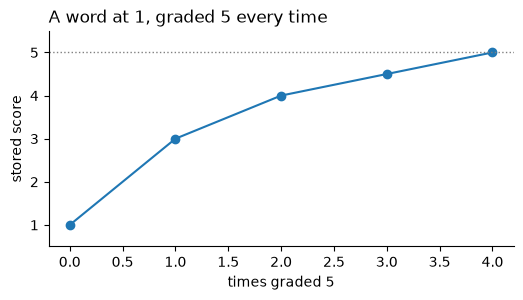

In [3]:
score, trail = 1.0, [1.0]
while score < 5:
    score = blend_confidence(score, 5)
    trail.append(score)

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(range(len(trail)), trail, marker="o")
ax.axhline(5, ls=":", lw=1, color="grey")
ax.set_xlabel("times graded 5"); ax.set_ylabel("stored score")
ax.set_ylim(0.5, 5.5); ax.set_title("A word at 1, graded 5 every time", loc="left")
ax.spines[["top", "right"]].set_visible(False)
print(" -> ".join(format_confidence(v) for v in trail))

### Halves, not quarters

Averaging repeatedly would otherwise produce `1.75`, then `2.8125` — meaningless precision
for a self-assessed 1–5 scale. Results are snapped to the nearest `0.5`, ties rounding
**up**.

Ties rounding up is not cosmetic: with ties rounding down the sequence above sticks at
`4.5` forever and "repeat until mastered" never terminates.

In [4]:
pd.DataFrame([{"old": o, "grade": g, "raw average": (o + g) / 2,
               "stored": blend_confidence(o, g)}
              for o, g in [(3.5, 4), (3.5, 3), (4.5, 5), (2.5, 2), (1.5, 2)]])

,old,grade,raw average,stored
0,3.5,4,3.75,4.0
1,3.5,3,3.25,3.5
2,4.5,5,4.75,5.0
3,2.5,2,2.25,2.5
4,1.5,2,1.75,2.0


## 2. A whole session, through the app's own code

The loop below is not a re-implementation. It runs `session.ReviewSession`, the object the
app's server (`service.py`) holds for a session in progress; the page only sends it grades.

The simulated learner grades honestly (usually well, sometimes not) and then **stops after
30 cards** rather than drilling every word to 5, which is what "End session" does and what
most real sessions look like.

In [5]:
import random
from datetime import datetime, timezone

from flashcards.session import ReviewSession, build_deck
from flashcards.srs import make_scheduler

SIZE, SEED = 12, 42
NOW = datetime(2026, 10, 2, 9, 0, tzinfo=timezone.utc)
deck = build_deck(data.cards, mode="mix", order="weighted", limit=SIZE, seed=SEED)

# Unfuzzed FSRS so the notebook's output is the same on every run.
session = ReviewSession(deck, direction="mixed", repeat=True, seed=SEED,
                        scheduler=make_scheduler(fuzz=False))
print(f"deck of {len(deck)} unique words, repeat-until-mastered ON")

deck of 12 unique words, repeat-until-mastered ON


In [6]:
by_id = {c.id: c for c in data.cards}
rng = random.Random(0)
trace = []

MAX_CARDS = 30            # the learner presses "End session" here
while not session.finished and len(trace) < MAX_CARDS:
    cid = session.current
    before = session.effective_confidence(cid)
    grade = rng.choices([2, 3, 4, 5], weights=[1, 2, 3, 5])[0]   # an honest-ish learner
    session.grade(grade, NOW)
    trace.append({
        "step": len(trace) + 1, "word": by_id[cid].term,
        "before": format_confidence(before), "pressed": grade,
        "after": format_confidence(session.effective_confidence(cid)),
        "phase": "first pass" if len(trace) < SIZE else "repeat",
    })
session.end()

trace = pd.DataFrame(trace)
print(f"{len(trace)} presentations for {SIZE} unique words "
      f"({len(trace) / SIZE:.1f} per word)")
trace.head(16)

30 presentations for 12 unique words (2.5 per word)


,step,word,before,pressed,after,phase
0,1,ausfuehrlich,ungraded,5,5,first pass
1,2,Haltestelle,1,5,3,first pass
2,3,Flugzeug,ungraded,4,4,first pass
3,4,zuverlaessig,4,3,3.5,first pass
4,5,Gepaeck,2,4,3,first pass
5,6,Schreibtisch,1,4,2.5,first pass
6,7,knapp,1,5,3,first pass
7,8,allmaehlich,3,4,3.5,first pass
8,9,Unterlagen,2,4,3,first pass
9,10,vermeiden,3,5,4,first pass


### The two phases are visible in the trace

**Every drawn word is shown exactly once first.** Capping a session at 12 words means you
really do see all 12 before anything repeats.

In [7]:
first_pass = trace.head(SIZE)
print("distinct words in the first", SIZE, "steps :", first_pass["word"].nunique())
print("any word shown twice in a row            :",
      (trace["word"] == trace["word"].shift()).any())

distinct words in the first 12 steps : 12
any word shown twice in a row            : False


**Then the repeats go to whoever is weakest.** Words that started low get drilled
several times; words that were already strong are done after one pass.

In [8]:
per_word = (trace.groupby("word")
            .agg(times_shown=("word", "size"), first_seen_at=("before", "first"))
            .join(pd.Series({c.term: c.confidence for c in deck}, name="score at deck time")))
per_word["score at deck time"] = per_word["score at deck time"].map(format_confidence)
per_word.sort_values("times_shown", ascending=False)

,times_shown,first_seen_at,score at deck time
word,,,
Gepaeck,4,2,2
Flugzeug,3,ungraded,nan
Vorhang,3,1,1
Unterlagen,3,2,2
vermeiden,3,3,3
knapp,3,1,1
riesig,3,1,1
Haltestelle,2,1,1
Schreibtisch,2,1,1


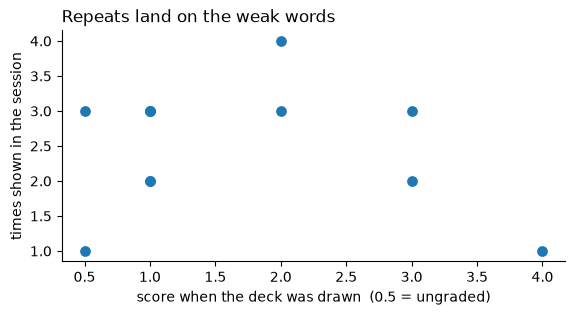

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3))
start = {c.term: (0.5 if c.confidence is None else c.confidence) for c in deck}
ax.scatter([start[w] for w in per_word.index], per_word["times_shown"], s=45)
ax.set_xlabel("score when the deck was drawn  (0.5 = ungraded)")
ax.set_ylabel("times shown in the session")
ax.set_title("Repeats land on the weak words", loc="left")
ax.spines[["top", "right"]].set_visible(False)

## 3. What the session proposes to write

Only words whose score actually **changed** are written. A grade that averages back onto
the value already in the file is not a change, even though the word was reviewed.

In [10]:
# Confidence changes only; session.cell_updates() adds the FSRS columns M..R (notebook 04).
changes = {cid: new for cid, new in session.confidence.items() if new != by_id[cid].confidence}
summary = pd.DataFrame([
    {"topic": by_id[cid].topic, "term": by_id[cid].term,
     "old": format_confidence(by_id[cid].confidence), "new": format_confidence(new),
     "cell": f"{by_id[cid].sheet}!L{by_id[cid].row}"}
    for cid, new in changes.items()
]).sort_values(["topic", "term"]).reset_index(drop=True)
print(f"{len(changes)} of {SIZE} reviewed words changed")
summary

12 of 12 reviewed words changed


,topic,term,old,new,cell
0,Adjectives & Adverbs,allmaehlich,3,4.5,Adjectives & Adverbs!L8
1,Adjectives & Adverbs,ausfuehrlich,ungraded,5,Adjectives & Adverbs!L6
2,Adjectives & Adverbs,knapp,1,4,Adjectives & Adverbs!L7
3,Adjectives & Adverbs,riesig,1,4,Adjectives & Adverbs!L2
4,Adjectives & Adverbs,zuverlaessig,4,3.5,Adjectives & Adverbs!L3
5,Household,Vorhang,1,4.5,Household!L9
6,School & Office,Schreibtisch,1,4,School & Office!L7
7,School & Office,Unterlagen,2,4.5,School & Office!L6
8,Travel & Transport,Flugzeug,ungraded,4.5,Travel & Transport!L7
9,Travel & Transport,Gepaeck,2,4.5,Travel & Transport!L4


## 4. Writing into the .xlsx without breaking it

This is the part of the app that had to be built by hand. The real reference workbook uses
dynamic-array formulas (`LET`/`LAMBDA`), rich-value metadata and an Office web add-in part.
**openpyxl drops or mangles all of those on save**, so it is never used to write.

Instead `writeback.py` opens the `.xlsx` as a zip, rewrites only the specific `<v>` values
in column L of the affected sheets, and copies every other archive member byte for byte.

Before anything is touched, a timestamped backup is made.

In [11]:
import zipfile
from flashcards.writeback import apply_confidence_updates

def member(path, name):
    with zipfile.ZipFile(path) as z:
        return z.read(name).decode("utf-8")

# Snapshot every archive member so we can prove what changed and what did not.
with zipfile.ZipFile(WORKBOOK) as z:
    before_bytes = {n: z.read(n) for n in z.namelist()}

updates = {(by_id[cid].sheet, by_id[cid].row): new for cid, new in changes.items()}
result = apply_confidence_updates(
    str(WORKBOOK), updates,
    original_mtime=data.mtime,
    backup_dir=str(ROOT / "experiments" / "_demo" / "backups"),
)
print(f"cells written : {result.cells_written}")
print(f"sheets touched: {result.sheets_touched}")
print(f"backup        : {Path(result.backup_path).name}")

cells written : 12
sheets touched: ['Adjectives & Adverbs', 'Household', 'School & Office', 'Travel & Transport', 'Verbs']
backup        : demo_vocab.20261002-231953-111869.xlsx


### Proof 1 — only the sheets that needed changing were changed

Every other part of the archive is byte-identical, including the formula dashboard.

In [12]:
with zipfile.ZipFile(WORKBOOK) as z:
    after_bytes = {n: z.read(n) for n in z.namelist()}

diff = pd.DataFrame([
    {"archive member": n, "changed": before_bytes[n] != after_bytes.get(n)}
    for n in before_bytes
])
print(f"{diff.changed.sum()} of {len(diff)} members changed")
diff[diff.changed]

5 of 16 members changed


,archive member,changed
4,xl/worksheets/sheet2.xml,True
5,xl/worksheets/sheet3.xml,True
6,xl/worksheets/sheet4.xml,True
7,xl/worksheets/sheet5.xml,True
8,xl/worksheets/sheet6.xml,True


In [13]:
# The dashboard sheet keeps its formulas, untouched.
dash = member(WORKBOOK, "xl/worksheets/sheet1.xml")
print("Overview sheet byte-identical :", before_bytes["xl/worksheets/sheet1.xml"] == after_bytes["xl/worksheets/sheet1.xml"])
print("still contains its formulas   :", "COUNTA" in dash and "AVERAGE" in dash)

Overview sheet byte-identical : True
still contains its formulas   : True


### Proof 2 — the scores round-trip, halves included

A whole number is written bare (`<v>4</v>`, never `<v>4.0</v>`) so untouched and rewritten
cells look alike.

In [14]:
reloaded = {c.term: c for c in load_cards(str(WORKBOOK)).cards}
check = summary.assign(
    in_file=lambda d: d["term"].map(lambda g: format_confidence(reloaded[g].confidence))
)
print("every change landed correctly:", (check["new"] == check["in_file"]).all())
check[["term", "old", "new", "in_file"]].head(8)

every change landed correctly: True


,term,old,new,in_file
0,allmaehlich,3,4.5,4.5
1,ausfuehrlich,ungraded,5,5
2,knapp,1,4,4
3,riesig,1,4,4
4,zuverlaessig,4,3.5,3.5
5,Vorhang,1,4.5,4.5
6,Schreibtisch,1,4,4
7,Unterlagen,2,4.5,4.5


In [15]:
# Half-values really are stored as halves in the XML, not rounded away.
halves = [g for g in summary["term"] if reloaded[g].confidence % 1]
print("words stored on a half-step:", halves[:5] or "none this run")
if halves:
    sheet = {t: f"xl/worksheets/sheet{i}.xml" for i, t in enumerate(data.topics, start=2)}
    g = halves[0]
    row = reloaded[g].row
    xml = member(WORKBOOK, sheet[reloaded[g].topic])
    frag = xml[xml.index(f'<c r="L{row}"'):][:60]
    print(f"{g}: {frag}")

words stored on a half-step: ['allmaehlich', 'zuverlaessig', 'Vorhang', 'Unterlagen', 'Flugzeug']
allmaehlich: <c r="L8"><v>4.5</v></c></row><row r="9"><c r="A9" t="inline


### Proof 3 — Excel is told to recalculate

The dashboards are formulas that depend on column L. Rewriting a value would otherwise
leave Excel showing stale cached results, so `fullCalcOnLoad` is set in `workbook.xml`.

In [16]:
print('fullCalcOnLoad="1"' in member(WORKBOOK, "xl/workbook.xml"))

True


### Proof 4 — a stale session cannot clobber your edits

The write-back re-checks the file's modification time against the moment it was read. If
you edited the workbook in Excel in the meantime, the save is **refused** — you reload and
review again rather than silently losing the hand edit.

In [17]:
from flashcards.writeback import WritebackError

try:
    apply_confidence_updates(
        str(WORKBOOK), {("Verbs", 2): 3.0},
        original_mtime=data.mtime,        # stale: we already wrote once above
        backup_dir=str(ROOT / "experiments" / "_demo" / "backups"),
    )
except WritebackError as exc:
    print("refused, as it should be:\n ", exc)

refused, as it should be:
  The workbook changed on disk since it was loaded. Reload it and review again so your session is based on the current file.


It also refuses to overwrite a cell containing a formula, and refuses a score that is
not on the half-step grid — both would mean a caller bypassed the grading rule.

In [18]:
from flashcards.writeback import _edit_cell_value

for label, call in [
    ("formula cell", lambda: _edit_cell_value(
        '<row r="2"><c r="L2"><f>A2+1</f><v>3</v></c></row>', 2, "L", 4.0, "Demo")),
    ("off-grid score", lambda: apply_confidence_updates(
        str(WORKBOOK), {("Verbs", 2): 2.8125},
        original_mtime=Path(WORKBOOK).stat().st_mtime,
        backup_dir=str(ROOT / "experiments" / "_demo" / "backups"))),
]:
    try:
        call()
        print(f"{label:16s} NOT refused -- that would be a bug")
    except WritebackError as exc:
        print(f"{label:16s} refused: {exc}")

formula cell     refused: Demo!L2 contains a formula; refusing to overwrite
off-grid score   refused: Verbs!row 2: confidence 2.8125 is not a multiple of 0.5


## Recap

| stage | module | guarantee |
|---|---|---|
| read | `workbook.py` | read-only; records mtime; dashboards skipped |
| draw | `session.py` | capped at N unique words, weighted toward the weakest |
| review | `session.ReviewSession` | first pass, then repeats re-weighted on live scores |
| grade | `models.py` | score is averaged, not replaced; half-step grid |
| write | `writeback.py` | backed up, atomic, byte-preserving, mtime-guarded, refuses anything ambiguous |

Nothing reaches the workbook until you press **Save to workbook** on the summary
screen. Until then a session is entirely in memory.

Back to [01 · Reading the workbook](01_reading_the_workbook.ipynb) ·
[02 · Choosing what to study](02_choosing_what_to_study.ipynb) ·
[04 · Spaced repetition](04_spaced_repetition.ipynb)